# Régression logistique

## Import des bibliothèques

In [19]:
import os
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report, roc_curve, auc
from imblearn.over_sampling import SMOTE
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import time

warnings.filterwarnings('ignore')

## Chargement des données

In [20]:
df = pd.read_csv('UNSW_NB15_1.csv')

print("Chargement du fichier UNSW_NB15_1.csv")
print(f"Nombre d'échantillons : {df.shape[0]}")
print(f"Nombre de colonnes : {df.shape[1]}")
df.head()

Chargement du fichier UNSW_NB15_1.csv
Nombre d'échantillons : 82332
Nombre de colonnes : 45


,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.000011,udp,-,INT,2,0,496,0,90909.0902,...,1,2,0,0,0,1,2,0,Normal,0
1,2,0.000008,udp,-,INT,2,0,1762,0,125000.0003,...,1,2,0,0,0,1,2,0,Normal,0
2,3,0.000005,udp,-,INT,2,0,1068,0,200000.0051,...,1,3,0,0,0,1,3,0,Normal,0
3,4,0.000006,udp,-,INT,2,0,900,0,166666.6608,...,1,3,0,0,0,2,3,0,Normal,0
4,5,0.000010,udp,-,INT,2,0,2126,0,100000.0025,...,1,3,0,0,0,2,3,0,Normal,0


## Suppression des colonnes inutiles

In [21]:
print("Colonnes avant suppression :")
print(df.columns.tolist())

drop_cols = ['id', 'srcip', 'sport', 'dstip', 'dsport', 'stime', 'ltime']
df = df.drop(columns=[c for c in drop_cols if c in df.columns], errors='ignore')

print(f"\nColonnes après suppression : {df.shape[1]} colonnes restantes")
print(df.columns.tolist())

Colonnes avant suppression :
['id', 'dur', 'proto', 'service', 'state', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst', 'is_sm_ips_ports', 'attack_cat', 'label']

Colonnes après suppression : 44 colonnes restantes
['dur', 'proto', 'service', 'state', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'is_ftp_log

## Encodage des variables catégorielles

In [22]:
print("Colonnes catégorielles avant encodage :")
categorical_cols = ['proto', 'service', 'state', 'attack_cat']
print([col for col in categorical_cols if col in df.columns])

le = LabelEncoder()
for col in categorical_cols:
    if col in df.columns:
        df[col] = le.fit_transform(df[col])
        print(f"{col} encodée avec succès")

print("\nAperçu après encodage :")
df.head()

Colonnes catégorielles avant encodage :
['proto', 'service', 'state', 'attack_cat']
proto encodée avec succès
service encodée avec succès
state encodée avec succès
attack_cat encodée avec succès

Aperçu après encodage :


,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sttl,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,0.000011,117,0,4,2,0,496,0,90909.0902,254,...,1,2,0,0,0,1,2,0,6,0
1,0.000008,117,0,4,2,0,1762,0,125000.0003,254,...,1,2,0,0,0,1,2,0,6,0
2,0.000005,117,0,4,2,0,1068,0,200000.0051,254,...,1,3,0,0,0,1,3,0,6,0
3,0.000006,117,0,4,2,0,900,0,166666.6608,254,...,1,3,0,0,0,2,3,0,6,0
4,0.000010,117,0,4,2,0,2126,0,100000.0025,254,...,1,3,0,0,0,2,3,0,6,0


## Suppression des lignes avec valeurs manquantes

In [23]:
print(f"Valeurs manquantes avant suppression : {df.isnull().sum().sum()}")
df = df.dropna()
print(f"Valeurs manquantes après suppression : {df.isnull().sum().sum()}")
print(f"Nombre d'échantillons restants : {df.shape[0]}")

Valeurs manquantes avant suppression : 0
Valeurs manquantes après suppression : 0
Nombre d'échantillons restants : 82332


## Séparation X (caractéristiques) et y (étiquette)

In [24]:
X = df.drop(['label', 'attack_cat'], axis=1)
y = df['label']

print(f"Caractéristiques (X) : {X.shape[0]} échantillons, {X.shape[1]} colonnes")
print(f"Étiquette (y) : {y.shape[0]} échantillons")
print("\nDistribution des classes :")
print(y.value_counts())

Caractéristiques (X) : 82332 échantillons, 42 colonnes
Étiquette (y) : 82332 échantillons

Distribution des classes :
label
1    45332
0    37000
Name: count, dtype: int64


## Division 80%/20%

In [25]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Ensemble d'entraînement : {X_train.shape[0]} échantillons")
print(f"Ensemble de test : {X_test.shape[0]} échantillons")
print("\nDistribution des classes - Entraînement :")
print(y_train.value_counts())

Ensemble d'entraînement : 65865 échantillons
Ensemble de test : 16467 échantillons

Distribution des classes - Entraînement :
label
1    36265
0    29600
Name: count, dtype: int64


## Normalisation (StandardScaler)

In [26]:
print("Avant normalisation - Statistiques d'une colonne (ex: dur) :")
print(f"  Moyenne : {X_train.iloc[:, 0].mean():.4f}")
print(f"  Écart-type : {X_train.iloc[:, 0].std():.4f}")

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\nAprès normalisation - Statistiques d'une colonne (ex: dur) :")
print(f"  Moyenne : {X_train_scaled[:, 0].mean():.4f}")
print(f"  Écart-type : {X_train_scaled[:, 0].std():.4f}")

Avant normalisation - Statistiques d'une colonne (ex: dur) :
  Moyenne : 0.9873
  Écart-type : 4.6218

Après normalisation - Statistiques d'une colonne (ex: dur) :
  Moyenne : 0.0000
  Écart-type : 1.0000


## Boxplot avant/après normalisation

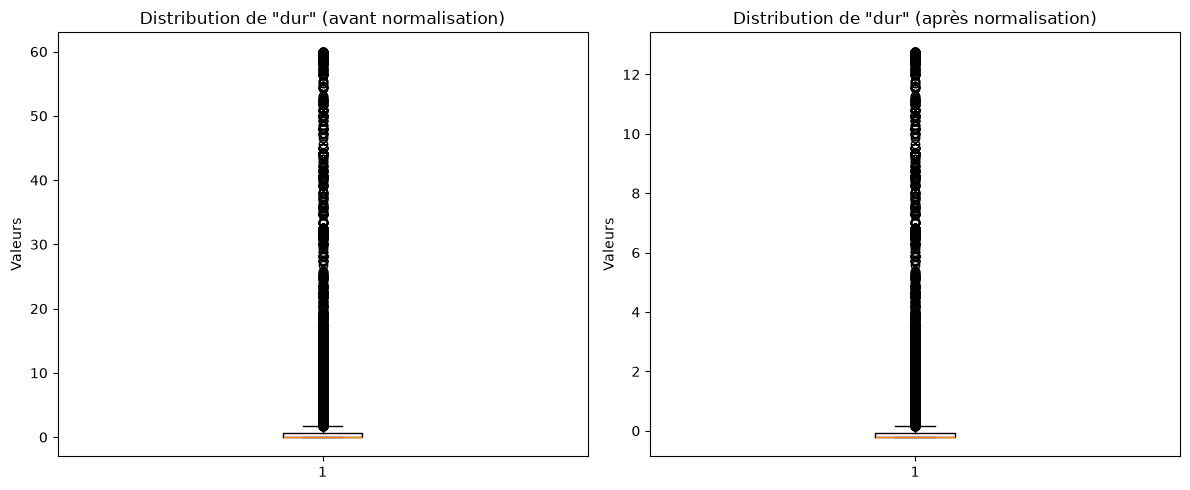

In [28]:
# Comparaison avant/après normalisation (ex: colonne 'dur')
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Avant normalisation
axes[0].boxplot(X_train.iloc[:, 0])
axes[0].set_title('Distribution de "dur" (avant normalisation)')
axes[0].set_ylabel('Valeurs')

# Après normalisation
axes[1].boxplot(X_train_scaled[:, 0])
axes[1].set_title('Distribution de "dur" (après normalisation)')
axes[1].set_ylabel('Valeurs')

plt.tight_layout()
plt.show()

## Histogramme d'une variable après normalisation

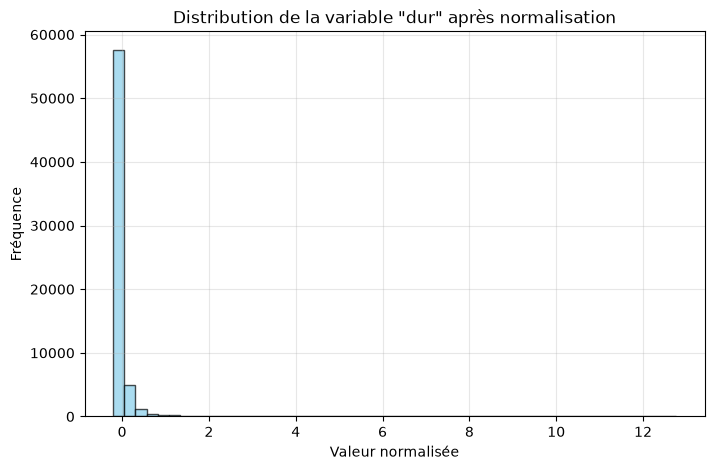

In [29]:
plt.figure(figsize=(8, 5))
plt.hist(X_train_scaled[:, 0], bins=50, color='skyblue', edgecolor='black', alpha=0.7)
plt.title('Distribution de la variable "dur" après normalisation')
plt.xlabel('Valeur normalisée')
plt.ylabel('Fréquence')
plt.grid(alpha=0.3)
plt.show()

## SMOTE (équilibrage des classes sur l'entraînement)

In [31]:
print("Distribution avant SMOTE :")
print(y_train.value_counts())

smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train_scaled, y_train)

print("\nSMOTE terminé")
print("Distribution après SMOTE :")
print(pd.Series(y_train_res).value_counts())
print(f"Nouveau nombre d'échantillons : {X_train_res.shape[0]}")

Distribution avant SMOTE :
label
1    36265
0    29600
Name: count, dtype: int64

SMOTE terminé
Distribution après SMOTE :
label
1    36265
0    36265
Name: count, dtype: int64
Nouveau nombre d'échantillons : 72530


## Distribution des classes avant/après SMOTE

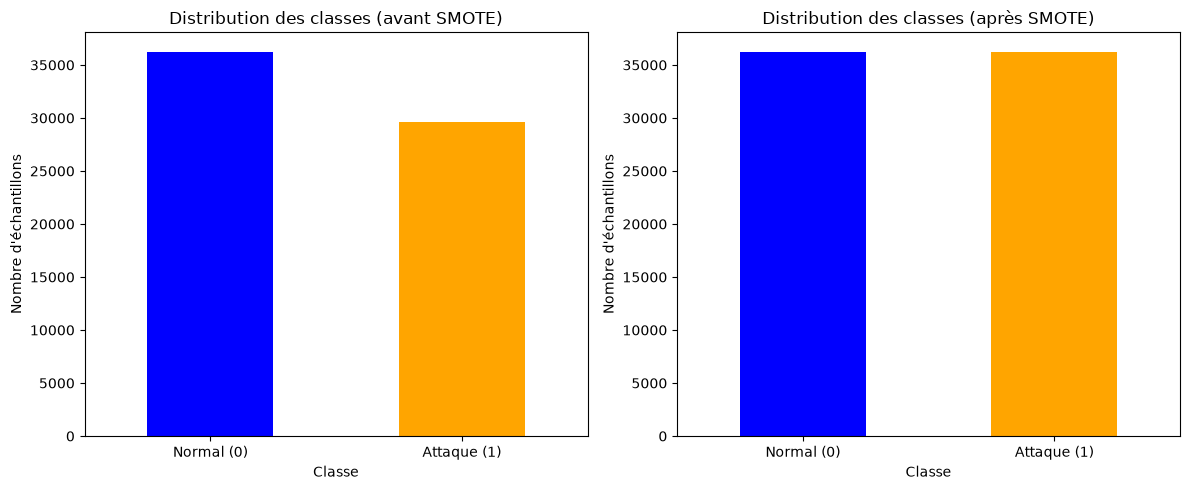

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Avant SMOTE
y_train.value_counts().plot(kind='bar', ax=axes[0], color=['blue', 'orange'])
axes[0].set_title('Distribution des classes (avant SMOTE)')
axes[0].set_xlabel('Classe')
axes[0].set_ylabel("Nombre d'échantillons")
axes[0].set_xticklabels(['Normal (0)', 'Attaque (1)'], rotation=0)

# Après SMOTE
pd.Series(y_train_res).value_counts().plot(kind='bar', ax=axes[1], color=['blue', 'orange'])
axes[1].set_title('Distribution des classes (après SMOTE)')
axes[1].set_xlabel('Classe')
axes[1].set_ylabel("Nombre d'échantillons")
axes[1].set_xticklabels(['Normal (0)', 'Attaque (1)'], rotation=0)

plt.tight_layout()
plt.show()

## Définition du modèle et de la grille d'hyperparamètres

In [33]:
print("Modèle : Régression Logistique")
print("Grille d'hyperparamètres : C = [0.01, 0.1, 1, 10]")

lr = LogisticRegression(random_state=42, max_iter=1000)
param_grid = {'C': [0.01, 0.1, 1, 10]}

Modèle : Régression Logistique
Grille d'hyperparamètres : C = [0.01, 0.1, 1, 10]


## GridSearchCV – Entraînement du modèle

In [34]:
print("\nDÉBUT DE L'ENTRAINEMENT DE LA RÉGRESSION LOGISTIQUE")
print("=" * 60)

start_time = time.time()
grid = GridSearchCV(lr, param_grid, cv=5, scoring='f1', n_jobs=-1)
grid.fit(X_train_res, y_train_res)
end_time = time.time()
train_time = end_time - start_time

best_lr = grid.best_estimator_

print(f"Entraînement terminé")
print(f"Temps d'exécution : {train_time:.2f} secondes")
print(f"Meilleurs paramètres : {grid.best_params_}")


DÉBUT DE L'ENTRAINEMENT DE LA RÉGRESSION LOGISTIQUE
Entraînement terminé
Temps d'exécution : 23.15 secondes
Meilleurs paramètres : {'C': 10}


## Évaluation sur l'ensemble de test

In [35]:
print("\nÉVALUATION SUR L'ENSEMBLE DE TEST")
print("=" * 60)

y_pred = best_lr.predict(X_test_scaled)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
auc_score = roc_auc_score(y_test, y_pred)

print(f" Accuracy  : {accuracy:.4f}")
print(f" Precision : {precision:.4f}")
print(f" Recall    : {recall:.4f}")
print(f" F1-score  : {f1:.4f}")
print(f" AUC       : {auc_score:.4f}")
print(f" Temps d'entraînement : {train_time:.2f} secondes")

print("\n Classification Report :")
print(classification_report(y_test, y_pred))


ÉVALUATION SUR L'ENSEMBLE DE TEST
 Accuracy  : 0.9027
 Precision : 0.9208
 Recall    : 0.9008
 F1-score  : 0.9107
 AUC       : 0.9029
 Temps d'entraînement : 23.15 secondes

 Classification Report :
              precision    recall  f1-score   support

           0       0.88      0.91      0.89      7400
           1       0.92      0.90      0.91      9067

    accuracy                           0.90     16467
   macro avg       0.90      0.90      0.90     16467
weighted avg       0.90      0.90      0.90     16467



## Histogramme des performances comparées

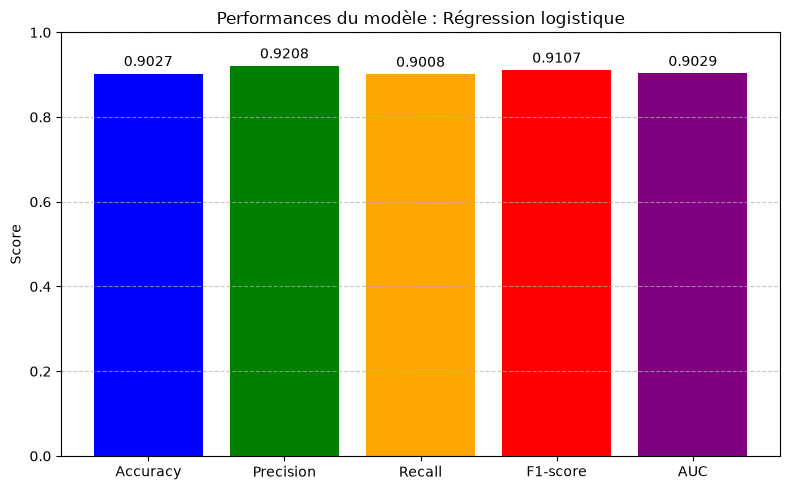

In [36]:
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-score', 'AUC']
values = [accuracy, precision, recall, f1, auc_score]

plt.figure(figsize=(8, 5))
bars = plt.bar(metrics, values, color=['blue', 'green', 'orange', 'red', 'purple'])
plt.ylim(0, 1)
plt.title('Performances du modèle : Régression logistique')
plt.ylabel('Score')
plt.grid(axis='y', linestyle='--', alpha=0.7)

for bar, val in zip(bars, values):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
             f'{val:.4f}', ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

## Matrice de confusion

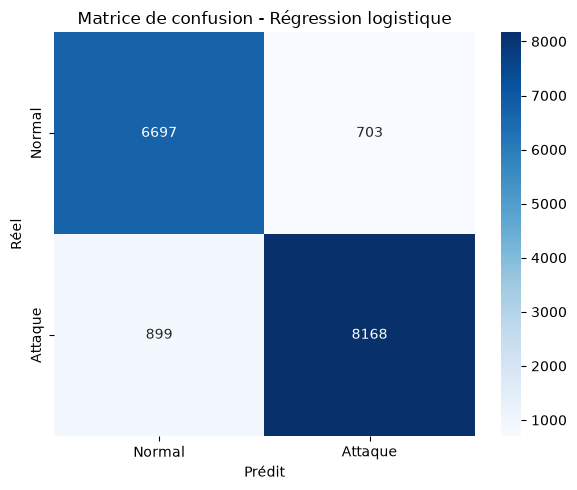

In [37]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Normal', 'Attaque'],
            yticklabels=['Normal', 'Attaque'])
plt.title('Matrice de confusion - Régression logistique')
plt.xlabel('Prédit')
plt.ylabel('Réel')
plt.tight_layout()
plt.show()

## La courbe ROC (Receiver Operating Characteristic)

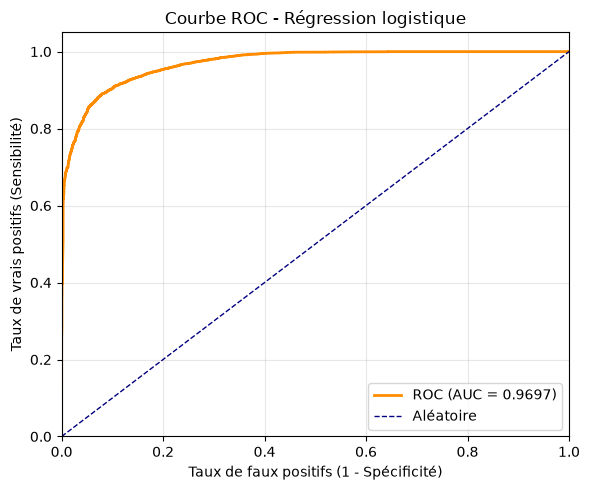

In [38]:
y_pred_proba = best_lr.predict_proba(X_test_scaled)[:, 1]
fpr, tpr, seuils = roc_curve(y_test, y_pred_proba)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=1, linestyle='--', label='Aléatoire')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Taux de faux positifs (1 - Spécificité)')
plt.ylabel('Taux de vrais positifs (Sensibilité)')
plt.title('Courbe ROC - Régression logistique')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Sauvegarde des résultats

In [39]:
print("\nRÉSULTATS À INTÉGRER DANS LE RAPPORT")
print("=" * 60)

print(f"""
\\textbf{{Régression logistique}}
Accuracy  : {accuracy:.4f} & Precision : {precision:.4f} & Recall : {recall:.4f} & F1-score : {f1:.4f} & AUC : {auc_score:.4f} \\\\
""")

results_df = pd.DataFrame({
    'Modèle': ['Régression logistique'],
    'Accuracy': [accuracy],
    'Precision': [precision],
    'Recall': [recall],
    'F1-score': [f1],
    'AUC': [auc_score],
    'Temps (s)': [train_time],
    'Meilleurs paramètres': [str(grid.best_params_)]
})

results_df.to_csv('resultats_logistic.csv', index=False)
print("Résultats sauvegardés dans resultats_logistic.csv")


RÉSULTATS À INTÉGRER DANS LE RAPPORT

\textbf{Régression logistique}
Accuracy  : 0.9027 & Precision : 0.9208 & Recall : 0.9008 & F1-score : 0.9107 & AUC : 0.9029 \\

Résultats sauvegardés dans resultats_logistic.csv
